# Virtual flow metering and build-up analysis

SOCAR hackathon: ten gas-lifted oil wells, January to September 2025.

* **Phase 1 (VFM):** estimate daily oil, water and gas for every well from sensors only.
  Well-test rates are used only as training labels. `pta_results.csv` is not used at all.
* **Phase 2 (PTA):** Horner analysis of every shut-in, using the Phase 1 oil rate.
  `pta_results.csv` is read only at the end, as an answer key for comparison.

The notebook runs the same code as the command line (`src/`) and the web app (`app.py`).
Raw files in `data/` are never changed; all cleaning is done in code.

In [1]:
import sys, warnings, json
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from data import DATA, NULL_CODE, SENSORS, load_high_freq, load_static, load_well_tests
from features import CALIBRATED, window_features, daily_features
from vfm_model import PhysicsIPR
import train, pta, predict, reports
from submission import build as build_submission

%matplotlib inline
pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

## 1. Data and cleaning

* 1-minute sensors: duplicate minutes dropped, the `-999.25` null code and physically impossible values blanked.
* Choke events are attached to every minute; choke 0% = shut in.
* Well tests: negative (sign-flipped) rates made positive; GL-06 gas reported in m³ instead of Mscf is converted.

In [2]:
src = DATA / "high_freq_data.csv"
raw = pd.read_csv(src if src.exists() else DATA / "high_freq_data.zip", nrows=2_000_000)
print("First 2M raw rows: duplicates", raw.duplicated(["well_name", "timestamp"]).sum(),
      "| -999.25 codes", int((raw[SENSORS] == NULL_CODE).sum().sum()))
del raw
hf, tests, static = load_high_freq(), load_well_tests(), load_static()
print(f"Clean sensor rows: {len(hf):,}  wells: {hf.well_name.nunique()}  "
      f"from {hf.timestamp.min():%Y-%m-%d} to {hf.timestamp.max():%Y-%m-%d}")
print(f"Well tests: {len(tests)}")
hf[SENSORS].describe().round(1)

First 2M raw rows: duplicates 1213 | -999.25 codes 4196


Clean sensor rows: 3,914,560  wells: 10  from 2025-01-01 to 2025-09-30
Well tests: 85


,whp_psia,whp_downstream_psia,dh_pressure_psia,dh_temperature_degf,annulus_pressure_psia,gas_lift_rate_mscfd
count,3913210.0,3913623.0,3913082.0,3913350.0,3913496.0,3912997.0
mean,306.7,187.4,2838.6,186.3,1141.8,902.2
std,63.4,8.7,356.6,11.7,101.5,278.0
min,39.2,9.2,512.0,115.0,46.3,0.0
25%,258.0,182.1,2646.6,175.0,1078.0,738.0
50%,294.4,188.0,2730.4,186.8,1113.9,906.4
75%,341.9,193.8,2929.2,195.3,1170.8,1005.2
max,999.1,295.4,4253.5,225.0,1983.0,2384.2


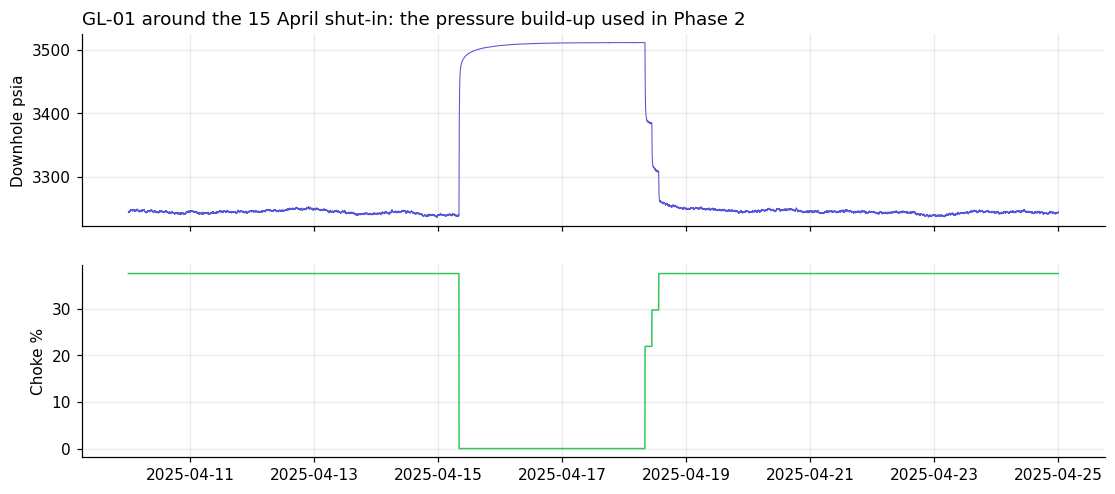

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
g = hf[(hf.well_name == "GL-01") & (hf.timestamp.between("2025-04-10", "2025-04-25"))]
ax[0].plot(g.timestamp, g.dh_pressure_psia, lw=.7, color="#5856D6"); ax[0].set_ylabel("Downhole psia")
ax[1].plot(g.timestamp, g.choke_opening_pct, lw=1, color="#34C759"); ax[1].set_ylabel("Choke %")
ax[0].set_title("GL-01 around the 15 April shut-in: the pressure build-up used in Phase 2", loc="left");

## 2. Features

Sensors are averaged over each well-test window (training rows) and over each flowing day (prediction rows).
`days` is the time since 1 Jan 2025, so each well can drift slowly (depletion, rising water cut).

In [4]:
X = window_features(hf, tests, static)
daily_in = daily_features(hf, static)
X[["well_name", "days", *SENSORS, "choke_opening_pct", "tubing_gradient"]].head()

,well_name,days,whp_psia,whp_downstream_psia,dh_pressure_psia,dh_temperature_degf,annulus_pressure_psia,gas_lift_rate_mscfd,choke_opening_pct,tubing_gradient
test_idx,,,,,,,,,,
0,GL-01,2.832639,280.117861,175.137651,3233.172717,203.170229,1166.473658,820.337500,40.6,0.314825
1,GL-01,30.975694,277.248417,173.699896,3221.335740,203.173361,1160.428010,819.310313,40.6,0.313869
2,GL-01,61.518750,274.966201,174.908332,3229.483257,203.106625,1155.653590,821.487500,40.6,0.314980
3,GL-01,91.786806,292.881889,170.284503,3232.117457,203.049541,1164.162264,830.488958,37.5,0.313351
4,GL-01,122.299306,288.820472,168.940639,3232.715042,202.996458,1155.504361,829.224061,37.5,0.313848


## 3. Choosing the model (Phase 1)

Four sets of inputs × several models are compared with checks that never let the model see the answers:

* `choose_model_apr_jun`: for each month April to June, train on all earlier tests and predict that month. **Used to pick the model.**
* `final_check_jul_sep`: the same for July to September, scored once with the chosen model. **The reported number.**
* `leave_one_well_out`: hide a whole well, to see how a model does on a brand-new well.

Set 4, *well-calibrated*, gives each well its own inflow line (liquid rate vs downhole pressure),
water-cut level and time trend; oil = liquid × (1 − WC), gas = oil × the well's own GOR.
This takes about 3 minutes.

In [5]:
res, preds = train.evaluate(X, tests)
table = res.pivot_table(index=["cv", "feature_set", "model"], columns="phase", values="mape_pct").round(1)
table["mean"] = table.mean(axis=1).round(1)
table.loc[["choose_model_apr_jun", "final_check_jul_sep"]]

phase                                                gas   oil  water  mean
cv                   feature_set       model                               
choose_model_apr_jun 1_strict          extra_trees  19.9   9.7    7.3  12.3
                                       hist_gb      17.3   9.8    8.8  12.0
                                       ridge        20.9  17.8   13.3  17.3
                     2_plus_gaslift    extra_trees  13.1   8.5    7.1   9.6
                                       hist_gb      15.5  10.3    9.3  11.7
                                       ridge        17.2  18.0   12.1  15.8
                     3_plus_well_props extra_trees   9.1   6.7    7.0   7.6
                                       hist_gb      11.1   7.0    8.5   8.9
                                       ridge         9.0   5.8    5.6   6.8
                     4_well_calibrated physics_ipr   6.4   4.7    6.1   5.7
final_check_jul_sep  1_strict          extra_trees  17.0  11.3    6.9  11.7
                                       hist_gb      16.1   9.3   25.6  17.0
                                       ridge        23.7  18.4   18.0  20.0
                     2_plus_gaslift    extra_trees  15.0  11.1    6.8  11.0
                                       hist_gb      16.9  10.2   25.2  17.4
                                       ridge        19.4  17.8   15.3  17.5
                     3_plus_well_props extra_trees  12.7   9.3    6.0   9.3
                                       hist_gb      12.3   7.8   23.5  14.5
                                       ridge        11.4   8.1    5.0   8.2
                     4_well_calibrated physics_ipr   6.1   3.8    3.1   4.3

In [6]:
sel, hold = table.loc["choose_model_apr_jun"], table.loc["final_check_jul_sep"]
rows = []
for s in sel.index.get_level_values(0).unique():
    m = sel.loc[s, "mean"].idxmin()
    rows.append({"feature_set": s, "chosen_model": m, "choose_model_apr_jun_mape": sel.loc[(s, m), "mean"],
                 **{f"final_check_{p}_mape": hold.loc[(s, m), p] for p in ["oil", "water", "gas"]},
                 "final_check_mean_mape": hold.loc[(s, m), "mean"]})
per_set = pd.DataFrame(rows)
best = per_set.loc[per_set.choose_model_apr_jun_mape.idxmin()]
print(f"Chosen on April-June: {best.feature_set} + {best.chosen_model}")
print(f"Error on unseen July-September well tests: {best.final_check_mean_mape}% (MAPE)")
per_set

Chosen on April-June: 4_well_calibrated + physics_ipr
Error on unseen July-September well tests: 4.3% (MAPE)


,feature_set,chosen_model,choose_model_apr_jun_mape,final_check_oil_mape,final_check_water_mape,final_check_gas_mape,final_check_mean_mape
0,1_strict,hist_gb,12.0,9.3,25.6,16.1,17.0
1,2_plus_gaslift,extra_trees,9.6,11.1,6.8,15.0,11.0
2,3_plus_well_props,ridge,6.8,8.1,5.0,11.4,8.2
3,4_well_calibrated,physics_ipr,5.7,3.8,3.1,6.1,4.3


WAPE % on July-September: {'gas': 4.8, 'oil': 3.4, 'water': 3.6}


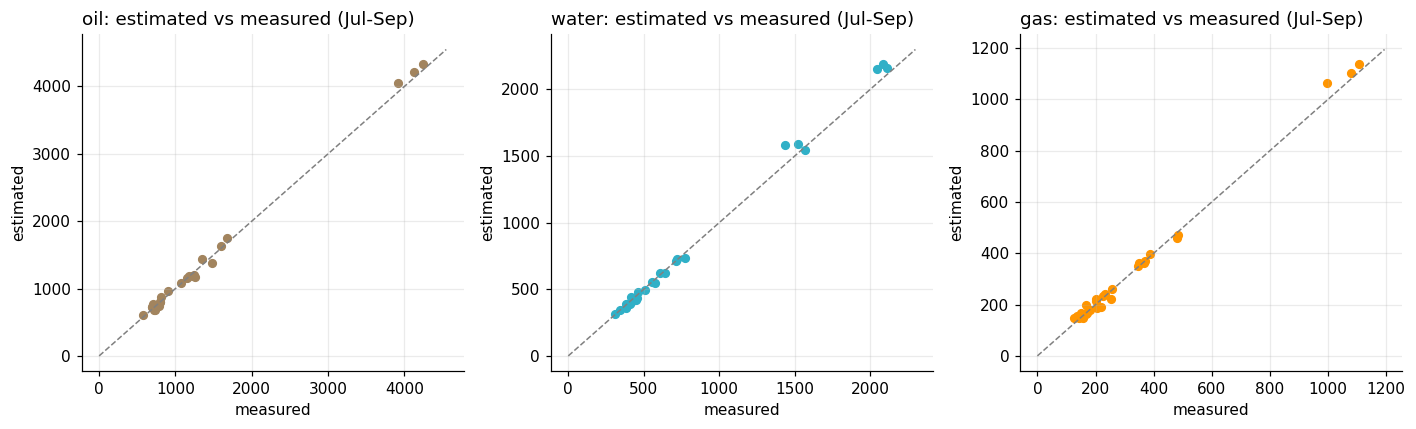

In [7]:
# WAPE (total absolute error / total rate) for the chosen model on July-September
f = preds[(preds.cv == "final_check_jul_sep") & (preds.feature_set == best.feature_set) & (preds.model == best.chosen_model)]
wape = f.groupby("phase").apply(lambda g: 100 * (g.predicted - g.measured).abs().sum() / g.measured.sum()).round(1)
print("WAPE % on July-September:", wape.to_dict())
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (ph, c) in zip(axes, [("oil", "#A2845E"), ("water", "#30B0C7"), ("gas", "#FF9500")]):
    g = f[f.phase == ph]; top = g[["measured", "predicted"]].max().max() * 1.05
    ax.scatter(g.measured, g.predicted, color=c, s=25); ax.plot([0, top], [0, top], "--", color="grey", lw=1)
    ax.set_title(f"{ph}: estimated vs measured (Jul-Sep)", loc="left"); ax.set_xlabel("measured"); ax.set_ylabel("estimated")
plt.tight_layout()

### Is it overfitting?

1. Error on the tests it learned from vs on the next, unseen month.
2. Simple baselines: repeat the well's last test, or its average.
3. Shuffle the sensors within each well: if the error barely changed, the model would only be memorising well averages.
4. Error month by month.

In [8]:
W = sorted(tests.well_name.unique()); PH = ["oil_rate_stbd", "water_rate_stbd", "gas_rate_mscfd"]
Xc = X[["well_name"] + CALIBRATED]
mape = lambda P, idx: np.mean([100 * np.mean(np.abs(P.loc[idx, c] - tests.loc[idx, c]) / tests.loc[idx, c]) for c in PH])
def roll(Xd, months):
    P = pd.concat([PhysicsIPR(W).fit(Xd.loc[tr], tests.loc[tr]).predict(Xd.loc[te]) for tr, te in train.rolling(tests, months)])
    return mape(P, P.index)
seen = np.mean([mape(PhysicsIPR(W).fit(Xc.loc[tr], tests.loc[tr]).predict(Xc.loc[tr]), tr) for tr, te in train.rolling(tests, [7, 8, 9])])
print(f"1. Error on tests it learned from {seen:.1f}%, on the unseen next month {roll(Xc, [7, 8, 9]):.1f}%")
def base(kind):
    out = []
    for tr, te in train.rolling(tests, [7, 8, 9]):
        t = tests.loc[tr].sort_values("test_start").groupby("well_name")[PH]
        out.append((t.last() if kind == "last" else t.mean()).reindex(tests.loc[te, "well_name"]).set_index(te))
    P = pd.concat(out); return mape(P, P.index)
print(f"2. Baselines: last test {base('last'):.1f}%, well average {base('mean'):.1f}%")
rng = np.random.default_rng(0); shuf = []
for i in range(10):
    Xs = Xc.copy()
    for c in ["dh_pressure_psia", "gas_lift_rate_mscfd", "tubing_gradient"]:
        Xs[c] = Xc.groupby("well_name")[c].transform(lambda s: s.sample(frac=1, random_state=int(rng.integers(1e9))).values)
    shuf.append(roll(Xs, [7, 8, 9]))
print(f"3. Sensors shuffled within each well: {np.mean(shuf):.1f}% (worse, so the sensors carry real information)")
print("4. By month:", {m: round(float(roll(Xc, [m])), 1) for m in [4, 5, 6, 7, 8, 9]})

1. Error on tests it learned from 3.2%, on the unseen next month 4.3%
2. Baselines: last test 7.7%, well average 11.7%


3. Sensors shuffled within each well: 6.3% (worse, so the sensors carry real information)
4. By month: {4: 5.7, 5: 5.1, 6: 6.3, 7: 4.9, 8: 4.5, 9: 3.5}


## 4. Final model, saved as `models/vfm_model.pkl`

Fitted on all 85 well tests and saved together with its inputs, the wells it knows and its check results.
The web app loads this file to estimate rates for uploaded data.

In [9]:
fit = PhysicsIPR(W).fit(predict.calibrated_input(X), tests)
path = predict.save_model(fit, train.model_card(tests, per_set, preds, best))
card = predict.load_model(path)
print(path.relative_to(path.parent.parent), "|", card["name"])
print("inputs:", card["inputs"])
print("trained on", card["trained_on_tests"], "tests,", card["trained_period"])

models/vfm_model.pkl | Well-calibrated inflow model (PhysicsIPR)
inputs: ['well_name', 'dh_pressure_psia', 'gas_lift_rate_mscfd', 'days', 'tubing_gradient', 'solution_gor_at_pb_scf_stb']
trained on 85 tests, ['2025-01-03', '2025-09-28']


## 5. Phase 1 result: daily oil, water and gas for every well

In [10]:
daily = predict.predict_daily(card["model"], daily_in)
daily.to_csv("outputs/daily_rates.csv", index=False)
tests.to_csv("outputs/well_tests_clean.csv", index=False)
out = build_submission(daily)
sub = pd.read_csv(out)
print(f"{out.relative_to(out.parent.parent)}: {len(sub)} rows, {sub.well_name.nunique()} wells, "
      f"{sub.timestamp.min()} to {sub.timestamp.max()}")
sub.head()

Filled by interpolation (no sensor data that day): GL-06 2025-06-24
results/vfm_submission.csv: 2730 rows, 10 wells, 2025-01-01 00:00:00 to 2025-09-30 00:00:00


,timestamp,well_name,oil_rate_stbd,water_rate_stbd,gas_rate_mscfd
0,2025-01-01 00:00:00,GL-01,1203.6,814.4,328.7
1,2025-01-02 00:00:00,GL-01,1200.7,811.6,327.9
2,2025-01-03 00:00:00,GL-01,1214.6,824.6,331.7
3,2025-01-04 00:00:00,GL-01,1204.9,815.8,329.0
4,2025-01-05 00:00:00,GL-01,1196.1,809.9,326.6


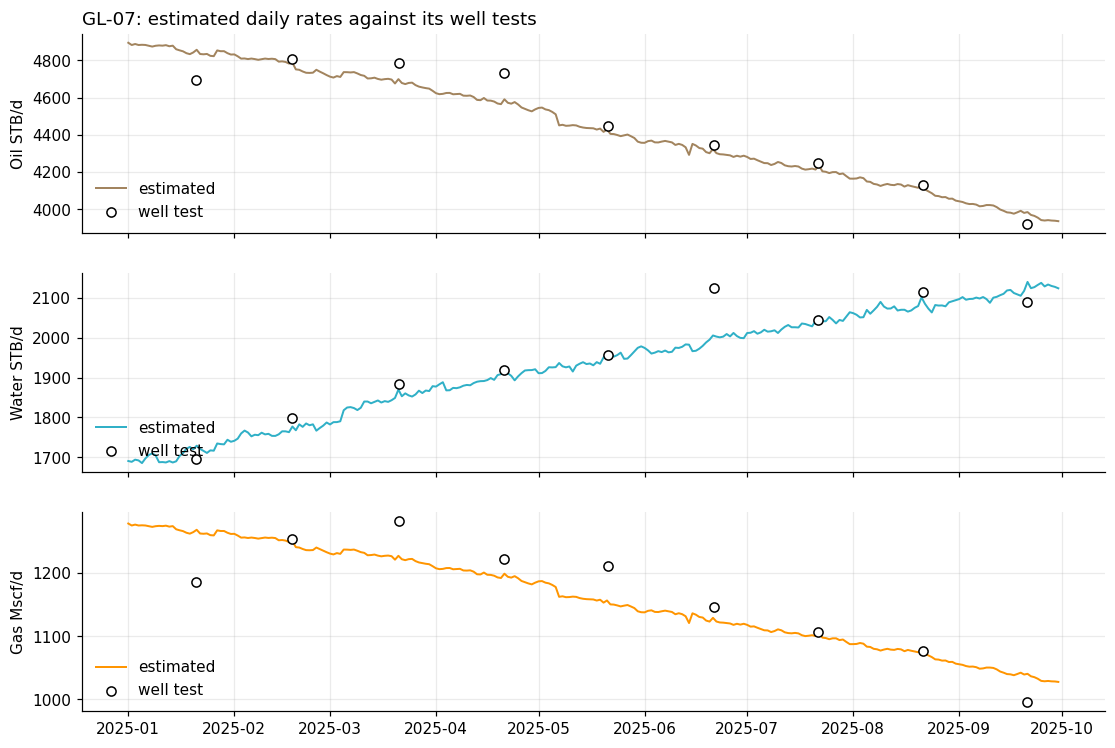

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
w = "GL-07"; g = daily[daily.well_name == w]; t = tests[tests.well_name == w]
for ax, (col, tcol, lab, c) in zip(axes, [("oil_stbd", "oil_rate_stbd", "Oil STB/d", "#A2845E"),
                                          ("water_stbd", "water_rate_stbd", "Water STB/d", "#30B0C7"),
                                          ("formation_gas_mscfd", "gas_rate_mscfd", "Gas Mscf/d", "#FF9500")]):
    ax.plot(g.date, g[col], color=c, lw=1.3, label="estimated")
    ax.scatter(t.test_start, t[tcol], facecolor="white", edgecolor="black", zorder=3, label="well test")
    ax.set_ylabel(lab); ax.legend(loc="lower left", frameon=False)
axes[0].set_title(f"{w}: estimated daily rates against its well tests", loc="left");

,well_name,days,avg_oil_stbd,avg_water_stbd,avg_formation_gas_mscfd,avg_gas_lift_mscfd,cum_oil_stb,cum_water_stb,cum_formation_gas_mscf,uptime_pct,water_cut_pct,gor_scf_stb
0,GL-01,273,951.2,739.1,259.7,806.3,259687.3,201766.1,70909.6,98.9,43.7,273.1
1,GL-02,273,1253.0,1467.1,378.5,915.4,342060.7,400516.4,103322.2,99.9,53.9,302.1
2,GL-03,273,726.4,369.3,160.8,619.7,198318.4,100812.5,43908.6,100.0,33.7,221.4
3,GL-04,273,737.8,338.2,180.9,1537.2,201429.5,92334.8,49378.5,99.3,31.4,245.1
4,GL-05,273,759.0,409.3,234.5,951.0,207217.7,111726.9,64018.0,100.0,35.0,308.9
5,GL-06,272,717.8,498.1,149.8,758.5,195254.8,135486.8,40751.7,99.9,41.0,208.7
6,GL-07,273,4445.4,1928.5,1160.7,986.4,1213582.6,526483.4,316872.7,100.0,30.3,261.1
7,GL-08,273,1437.6,380.3,477.9,483.0,392477.9,103814.6,130474.7,98.9,20.9,332.4
8,GL-09,273,1256.2,354.0,203.7,989.5,342932.8,96645.3,55620.0,100.0,22.0,162.2
9,GL-10,273,1924.3,631.8,438.4,991.4,525320.8,172478.2,119685.2,99.9,24.7,227.8


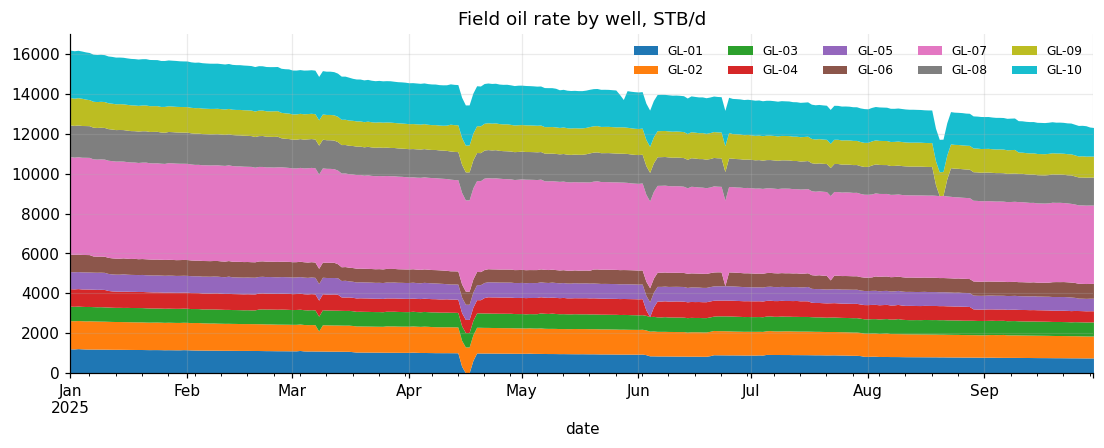

In [12]:
piv = daily.pivot_table(index="date", columns="well_name", values="oil_stbd")
ax = piv.plot.area(figsize=(12, 4), linewidth=0, title="Field oil rate by well, STB/d")
ax.legend(ncol=5, fontsize=8, frameon=False)
reports.per_well_summary(daily)

## 6. Phase 2: build-up analysis

Each choke closure that is reopened is a build-up. For each one:

* `q` = predicted oil rate on the last fully flowing day before the shut-in (Phase 1).
* `tp` = cumulative predicted oil since 1 January / q.
* The radial-flow window is the flattest half log cycle of the Bourdet derivative after wellbore storage;
  the Horner slope `m` is fitted there.
* `k = 162.6 q Bo μ / (m h)`, `s = 1.151 [(P1hr − Pwf)/m − log(k/(φ μ ct rw²)) + 3.23]`, `ΔP skin = 0.87 m s`.

Only 6 shut-ins fall inside our data (January to September). The answer key also lists 11 shut-ins in
October to December, after our data ends, so those cannot be analysed.

In [13]:
pvt = pd.read_csv(DATA / "reservoir_pvt.csv").set_index("well_name")
key = pd.read_csv(DATA / "pta_results.csv", parse_dates=["t_shut"])   # answer key, comparison only
table, web, skipped = pta.run(hf, daily, pvt, key=key)
(pta.ROOT / "outputs" / "pta_web.json").write_text(json.dumps(web))
table.drop(columns=["plot"]).to_csv(pta.RESULT.parent / "pta_results_detailed.csv", index=False)
print("Phase 2 result file:", pta.write_submission(table).relative_to(pta.ROOT))
table[["well_name", "t_shut", "q_pred_stbd", "m_psi_cycle", "key_m_psi_cycle", "k_md", "key_k_md",
       "skin", "key_skin", "dP_skin", "key_dP_skin", "interpretation"]].round(2)

Phase 2 result file: results/pta_submission.csv


,well_name,t_shut,q_pred_stbd,m_psi_cycle,key_m_psi_cycle,k_md,key_k_md,skin,key_skin,dP_skin,key_dP_skin,interpretation
0,GL-01,2025-04-15 08:00:00,1005.7,22.93,23.17,108.97,105.65,5.93,5.79,118.38,116.64,"Damaged well, stimulation candidate"
1,GL-02,2025-03-08 14:23:00,1321.8,52.69,53.69,58.25,55.81,-0.54,-0.64,-24.57,-30.02,Healthy near-well zone
2,GL-04,2025-06-03 08:00:00,804.7,145.95,147.88,54.90,53.02,-1.29,-1.35,-163.23,-174.22,Stimulated well
3,GL-06,2025-07-22 03:11:00,683.4,15.01,15.16,297.82,292.16,1.97,1.89,25.78,24.94,Slight near-well damage
4,GL-08,2025-08-19 09:00:00,1437.7,93.21,92.80,42.16,42.13,-1.63,-1.61,-132.50,-130.20,Stimulated well
5,GL-10,2025-05-27 21:04:00,1852.3,28.27,28.47,188.92,177.97,2.15,2.14,52.85,53.02,Slight near-well damage


In [14]:
err = pd.DataFrame({
    "slope m, %": 100 * (table.m_psi_cycle - table.key_m_psi_cycle).abs() / table.key_m_psi_cycle,
    "k, %": 100 * (table.k_md - table.key_k_md).abs() / table.key_k_md,
    "skin, abs": (table.skin - table.key_skin).abs(),
    "ΔP skin, %": 100 * (table.dP_skin - table.key_dP_skin).abs() / table.key_dP_skin.abs(),
})
print("Average difference from the answer key:", err.mean().round(2).to_dict())
pd.read_csv(pta.RESULT)

Average difference from the answer key: {'slope m, %': 1.05, 'k, %': 3.2, 'skin, abs': 0.07, 'ΔP skin, %': 5.23}


,well_name,shut_in_time,permeability_md,skin,delta_p_skin_psi,horner_slope
0,GL-01,2025-04-15 08:00:00,108.974574,5.933122,118.379069,22.933610
1,GL-02,2025-03-08 14:23:00,58.245452,-0.535933,-24.565998,52.687141
2,GL-04,2025-06-03 08:00:00,54.900642,-1.285523,-163.227635,145.946799
3,GL-06,2025-07-22 03:11:00,297.822781,1.973597,25.777917,15.013093
4,GL-08,2025-08-19 09:00:00,42.158831,-1.633825,-132.497957,93.214670
5,GL-10,2025-05-27 21:04:00,188.921130,2.149121,52.852482,28.267362


### Well-test plots (saved in `pta_plots/`)

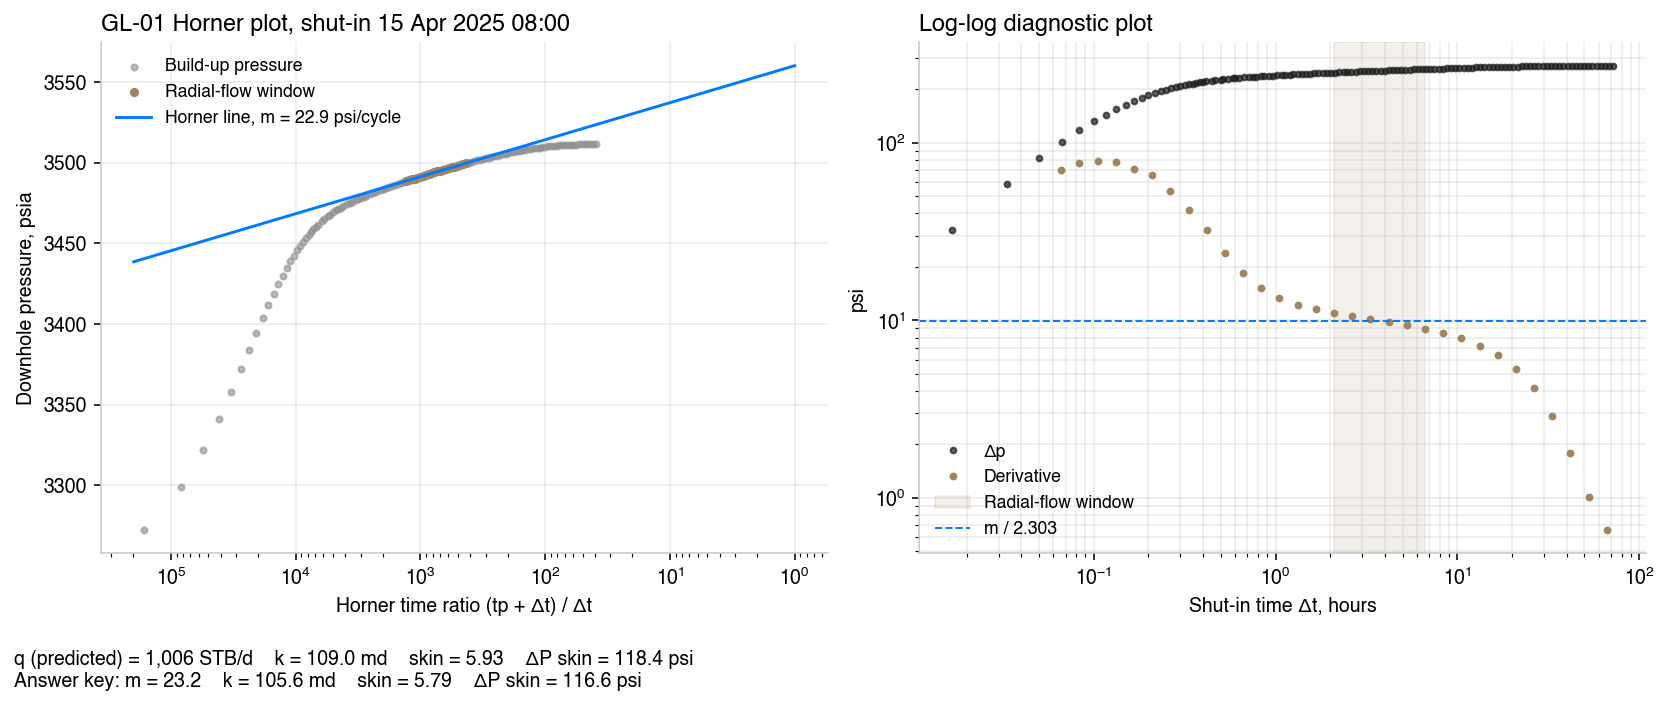

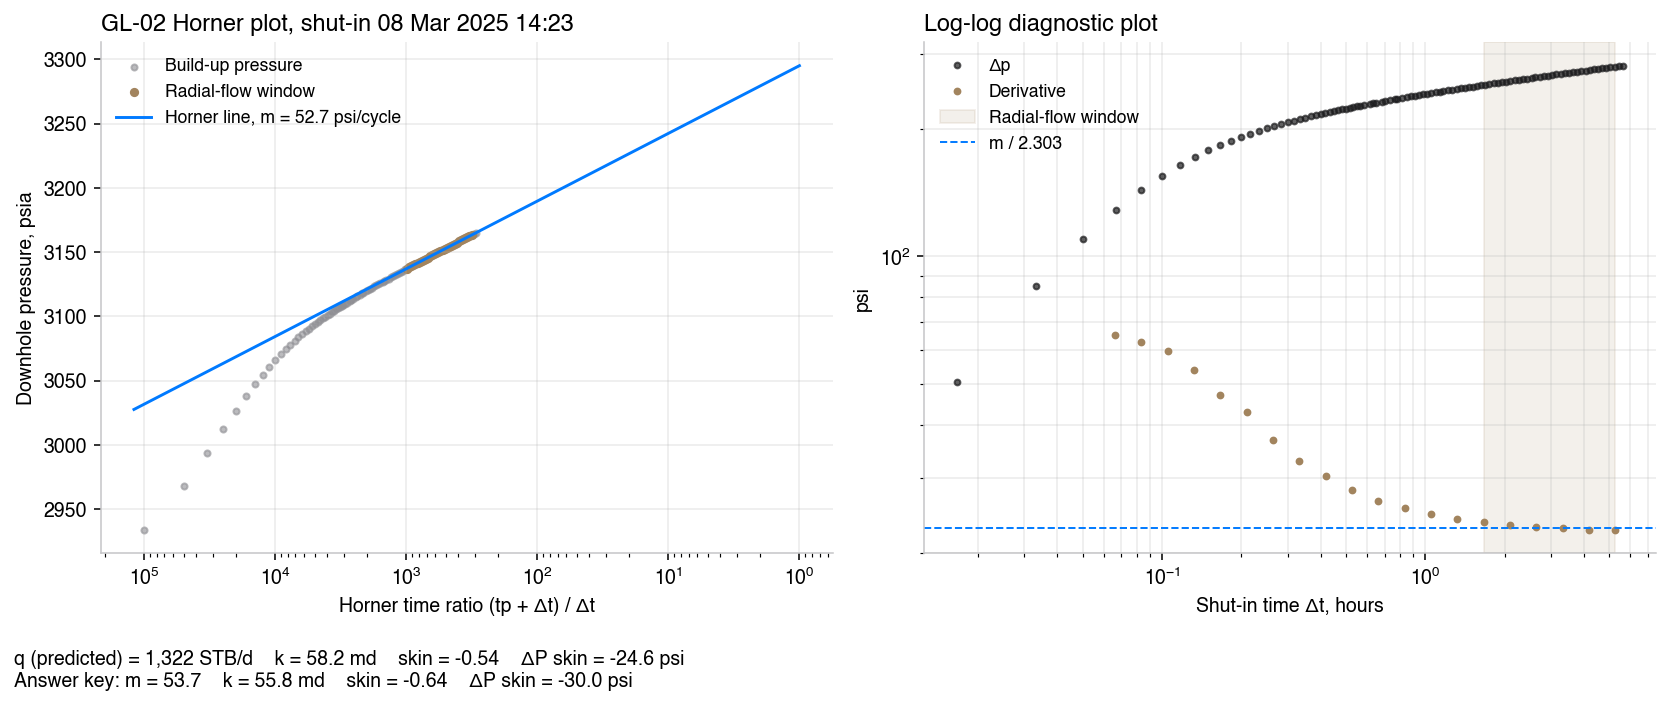

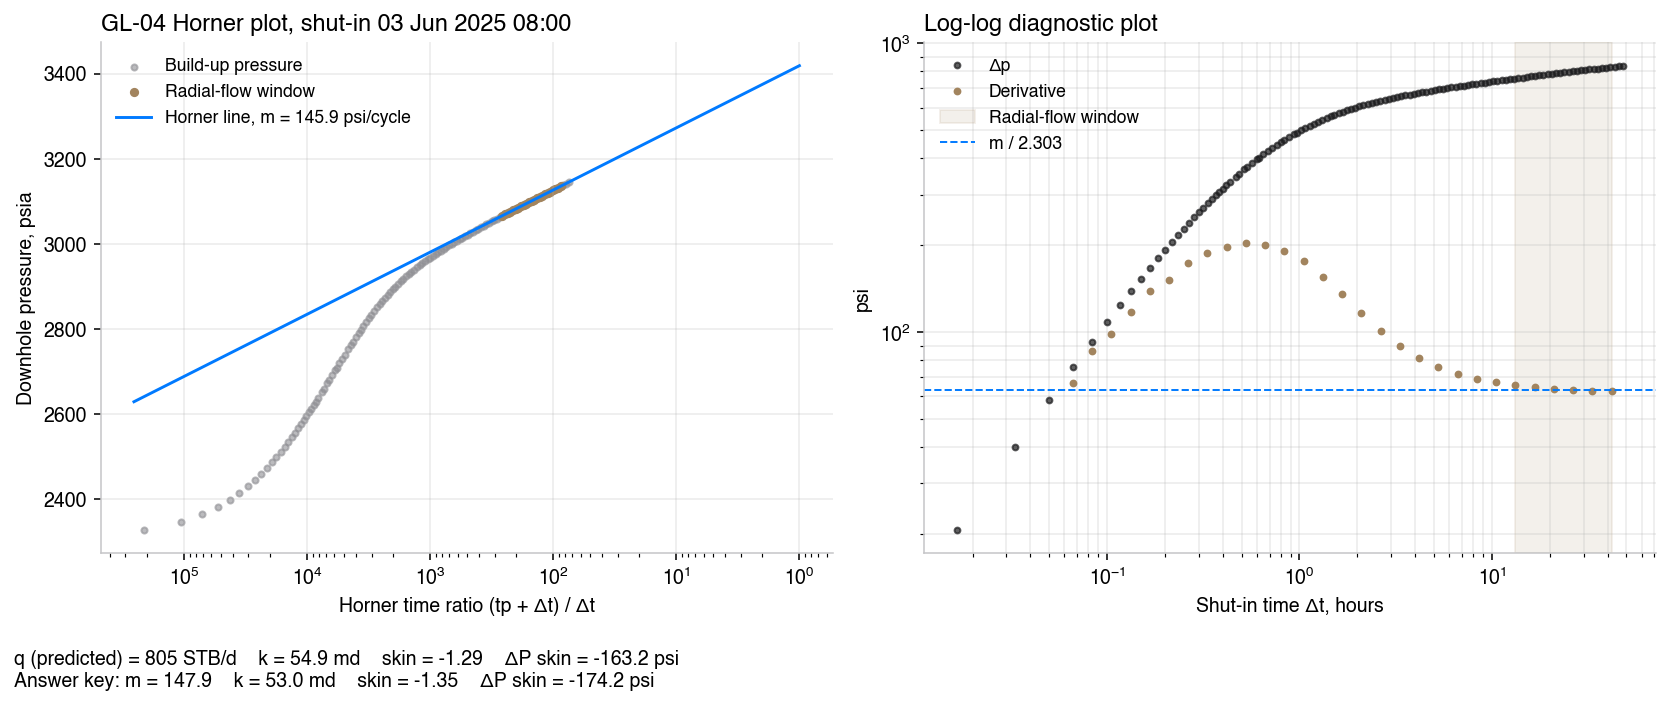

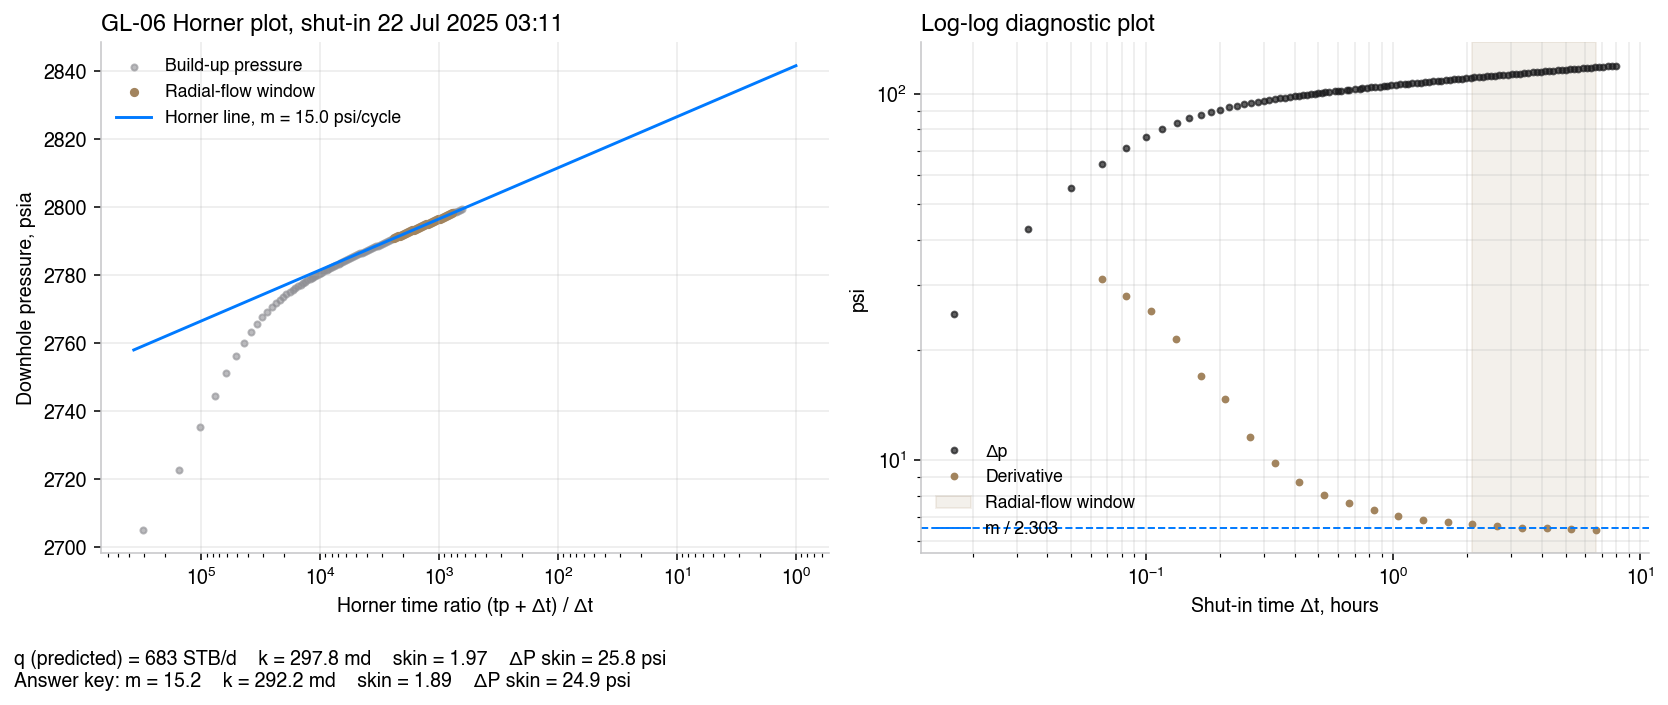

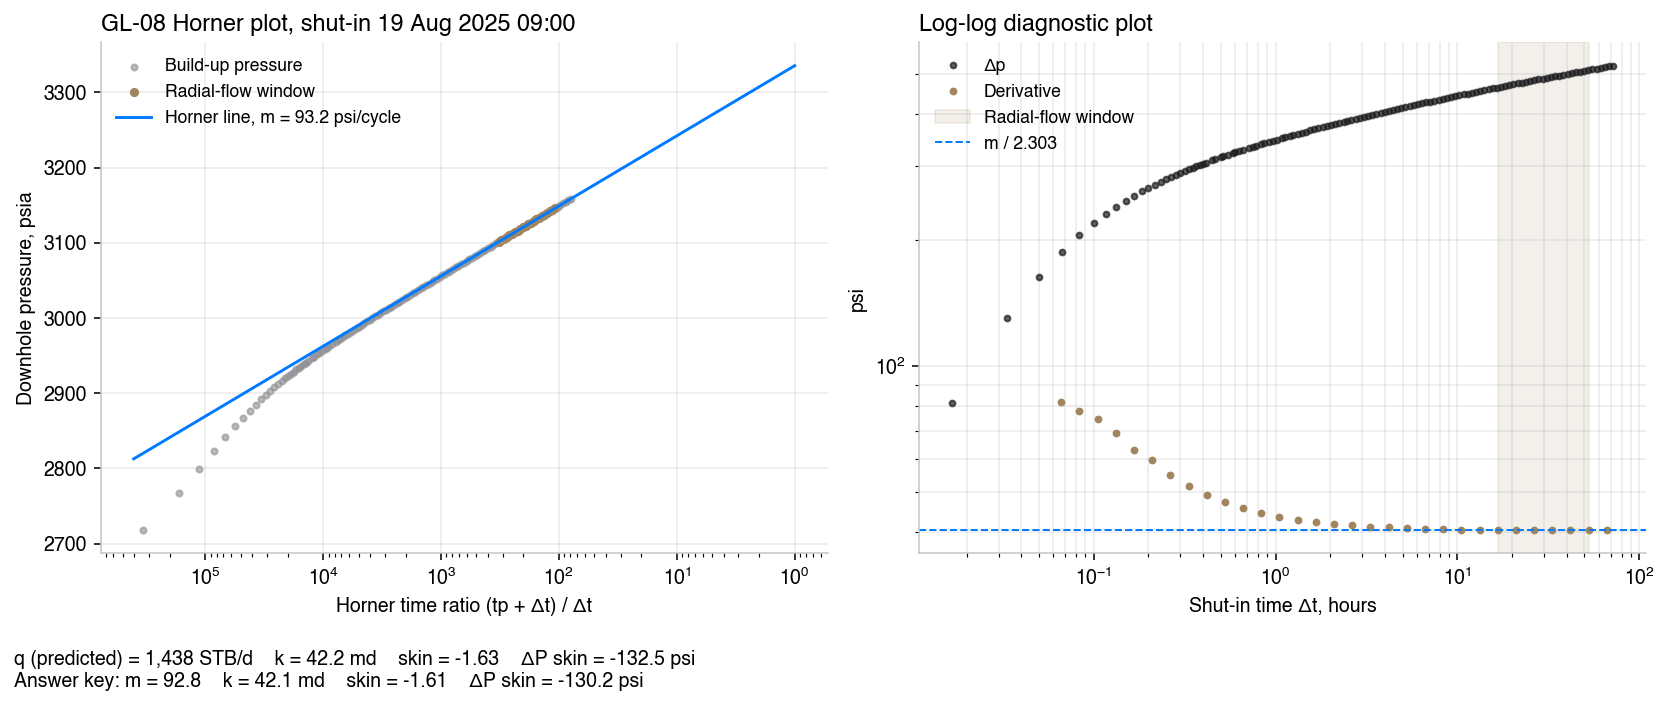

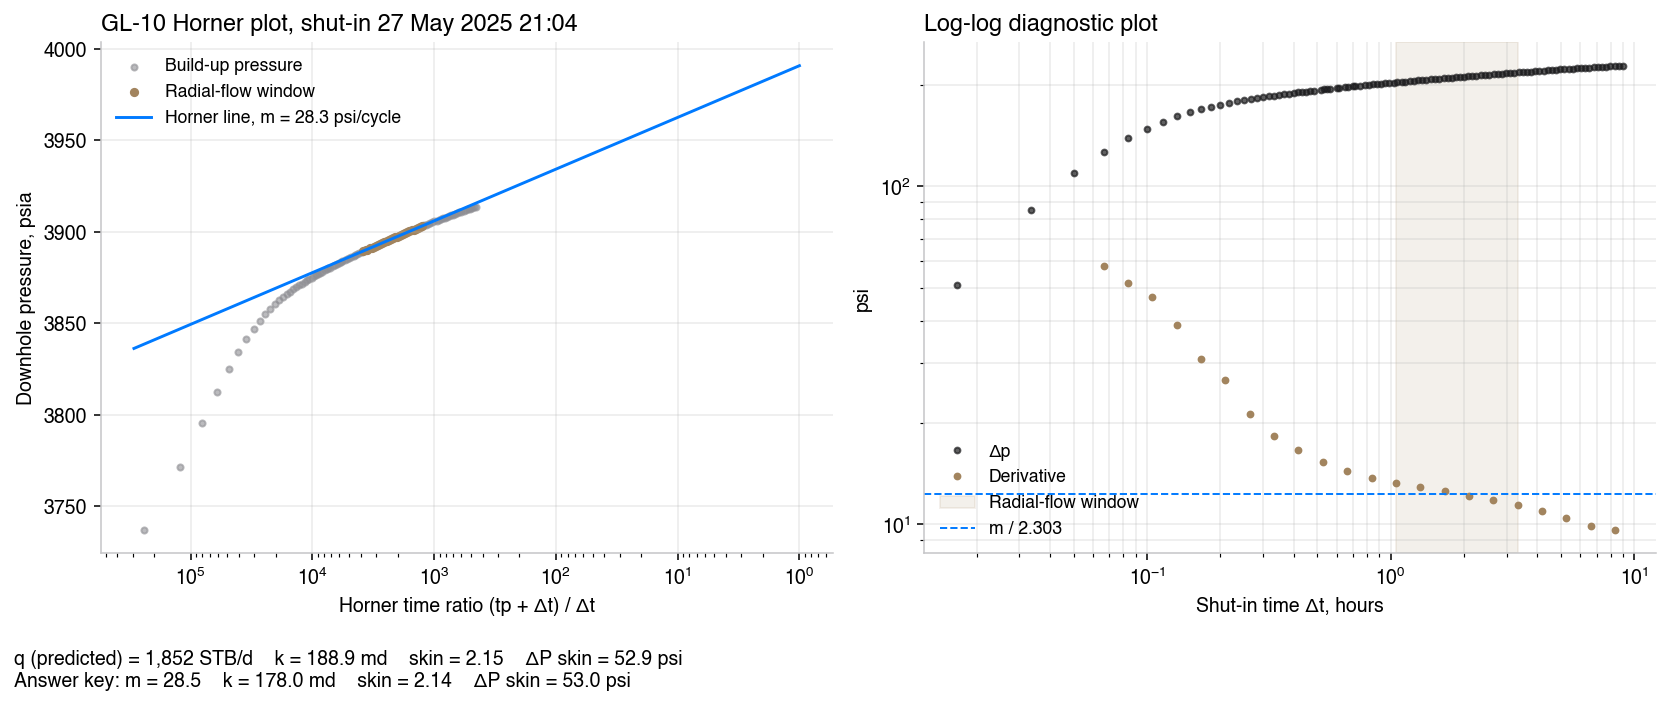

In [15]:
for p in web:
    display(Image(filename=str(pta.OUT / p["plot"]), width=950))

### Interpretation

In [16]:
for p in web:
    print(f"{p['well_name']} {p['t_shut']}: {p['interpretation'].upper()}")
    for n in p["notes"]:
        print("   -", n)
    print()

GL-01 2025-04-15 08:00: DAMAGED WELL, STIMULATION CANDIDATE
   - Permeability 109 md is good: the rock lets oil reach the well easily.
   - Skin 5.9: the near-well zone is damaged. About 118 psi of drawdown is lost there (flow efficiency 63%). Removing it, e.g. by acid treatment, could raise the rate by roughly 59% at the same drawdown.
   - The derivative drops at late time: pressure support from outside, such as an aquifer, a gas cap or an injector.
   - A hump before radial flow is the usual sign of wellbore storage together with positive skin.
   - Wellbore storage is over after about 2.1 h; radial flow is read from 2.1 to 6.6 h.
   - The test saw about 1,591 ft into the reservoir. Extrapolated reservoir pressure p* is 3,560 psia.
   - Radial flow lasted only 0.5 log cycles, so treat k and skin as approximate.

GL-02 2025-03-08 14:23: HEALTHY NEAR-WELL ZONE
   - Permeability 58 md is good: the rock lets oil reach the well easily.
   - Skin -0.5: the near-well zone is in good condit

## 7. Reports and the web app

In [17]:
from export_web import export
src = "Hackathon field data"
print(reports.vfm_excel(daily, sub, card, pta.ROOT / "results" / "vfm_report.xlsx", src).name)
print(reports.vfm_pdf(daily, tests, card, pta.ROOT / "results" / "vfm_report.pdf", src).name)
print(reports.pta_pdf(web, pta.OUT, pta.ROOT / "results" / "pta_report.pdf", src).name)
print(export().name, "(web app data)")

vfm_report.xlsx


vfm_report.pdf


pta_report.pdf
data.js (web app data)


**Deliverables**

| What | Where |
|---|---|
| Phase 1 result file | `results/vfm_submission.csv` |
| Phase 2 result file | `results/pta_submission.csv` |
| Trained model | `models/vfm_model.pkl` |
| PTA plots | `pta_plots/` |
| Reports | `results/vfm_report.xlsx`, `results/vfm_report.pdf`, `results/pta_report.pdf` |
| Web app | `python3 app.py`, then open http://127.0.0.1:8000 |